# 04 · Learning Representations: Autoencoders, VAEs, GANs and Self-Supervised Learning

This is a module of Neural Networks 1002. It assumes [module 02 of Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/02-neural-network-backprop/) (backpropagation), [module 03](https://neural-networks.academy.forwardforecasting.eu/03-training-deep-networks/) (training deep networks) and [module 05](https://neural-networks.academy.forwardforecasting.eu/05-convolutional-networks/) (convolutional networks, here only for the idea of an image encoder).

Until now the network was always told the right answer. Here it is not. The question is: **can a network learn something useful from data alone, without labels?** Four answers, in the order the field found them, and each one prepares the next module:

1. **Autoencoders**: squeeze the data through a narrow bottleneck and rebuild it. What survives the squeeze is a learned representation, and what cannot be rebuilt is an anomaly.
2. **Variational autoencoders (VAEs)**: make the bottleneck probabilistic so that the space between the codes is meaningful, and sampling from it generates new data. The price is blurriness.
3. **Generative adversarial networks (GANs)**: replace the reconstruction loss by a second network that tries to tell real from fake. Sharper samples, much harder training.
4. **Self-supervised learning**: invent a task whose answer is free (are these two views of the same image?) and learn representations by **contrastive learning**. This ends in **CLIP** (contrastive language-image pre-training), which aligns images and text.

In this notebook you will build, on a laptop CPU with fixed seeds:

* an autoencoder and measure **anomaly detection** by reconstruction error (area under the ROC curve, AUC) on a digit class it never saw, as a function of the bottleneck size, with and without denoising;
* a VAE with the **ELBO** (evidence lower bound) and the **reparameterisation trick**, a latent-space map, interpolations, and a measurement of the **blurriness trade-off** against the weight of the KL term;
* a GAN on a 2D toy distribution and on digits, with **mode collapse** shown and measured, the instability of the two-player game, and the hinge and Wasserstein variants;
* a **SimCLR**-style contrastive learner with an **InfoNCE** loss and hand-written augmentations, and a **linear-probe accuracy curve versus the number of labels** comparing supervised training from scratch, autoencoder features and contrastive features;
* a tiny **image-text contrastive model** (a CLIP in miniature) trained on digits and their captions, and then a **real pre-trained CLIP** run on the CPU for zero-shot classification.

**Contents**

1. Setup and data
2. Autoencoders: bottleneck, denoising, anomaly detection
3. Variational autoencoders: ELBO, reparameterisation, blurriness
4. Generative adversarial networks: a two-player game
5. Self-supervised learning: contrastive learning with SimCLR
6. CLIP: aligning images and text
7. Where this leads: diffusion and generalist models
8. Key takeaways, exercises, references

| Builds on | What we reuse |
|---|---|
| [02 Neural network and backprop (1001)](https://neural-networks.academy.forwardforecasting.eu/02-neural-network-backprop/) | gradients through a network, which PyTorch autograd computes for us (including a gradient of a gradient in the Wasserstein GAN) |
| [03 Training deep networks (1001)](https://neural-networks.academy.forwardforecasting.eu/03-training-deep-networks/) | Adam, learning rates, why noisy or opposing gradients make training fragile |
| [05 Convolutional networks (1001)](https://neural-networks.academy.forwardforecasting.eu/05-convolutional-networks/) | an encoder turns an image into a vector; here the encoders are small fully connected networks to stay fast |

New to PyTorch? The [Python 1001 course, section on AI frameworks](https://python.academy.forwardforecasting.eu/11-ai-frameworks/) introduces it. The data are the 8x8 handwritten digits shipped with scikit-learn, so there is no download except for the pre-trained CLIP in section 6 (about 600 MB, once). **Where the toys differ from real systems:** real autoencoders, GANs and contrastive models train convolutional or Transformer networks on millions of colour images for days on GPUs; our 64-pixel digits and few thousand steps show the mechanisms, not the scale, and some numbers (for example how much contrastive learning helps) depend on the data being tiny.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/04_autoencoders_gans_and_self_supervised.ipynb)

**Running in Google Colab?** Choose *Runtime > Run all*. The first code cell installs only what is missing (no session restart needed). The times shown in this notebook were measured on a multi-core machine; a free Colab CPU runtime (about 2 cores) can take several times longer.

In [ ]:
# Setup: works locally and in Google Colab. Installs only the packages that are missing.
import importlib.util, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'PIL': 'pillow',
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'skimage': 'scikit-image',
    'sklearn': 'scikit-learn',
    'torch': 'torch',
    'transformers': 'transformers',
}  # import name -> pip requirement
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Installing:', ', '.join(_missing))
    _r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], capture_output=True, text=True)
    if _r.returncode:
        print('WARNING: the pip install failed; continuing. Details:\n' + _r.stderr[-400:])
print(f"Environment: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()}")

## 1. Setup and data

The data are the **optical recognition of handwritten digits** set (Alpaydin and Kaynak, UCI Machine Learning Repository, licence CC BY 4.0), 1,797 images of 8x8 pixels bundled with scikit-learn, so nothing is downloaded. Pixel values run from 0 (blank) to 16 (full ink); we divide by 16. We keep 1,200 images for training and 597 for testing. Labels are used only where we say so.

We also train, once, a plain **logistic regression on the pixels** as a **judge**. It is not part of any model. We use it later as a ruler: if the judge is confident about a generated image, the image looks like a digit; if the judge is unsure, the image is ambiguous or garbled. It reaches about 97 % accuracy on the real test digits, so it is a decent ruler for this data.

train (1200, 64) test (597, 64) | judge accuracy on real test digits: 0.975


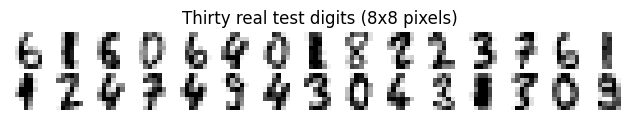

sharpness (total variation) of real digits: 0.237


In [1]:
import warnings
warnings.filterwarnings("ignore")
import time, math
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

torch.set_num_threads(1)          # these tiny networks run fastest on one thread
torch.manual_seed(0); np.random.seed(0)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
T0 = time.time()

digits = load_digits()
X = (digits.data / 16.0).astype(np.float32)          # (1797, 64), values in [0, 1]
y = digits.target
rng = np.random.RandomState(0)
order = rng.permutation(len(X))
itr, ite = order[:1200], order[1200:]
Xtr, Xte, ytr, yte = X[itr], X[ite], y[itr], y[ite]

judge = LogisticRegression(max_iter=2000).fit(Xtr, ytr)
print("train", Xtr.shape, "test", Xte.shape, "| judge accuracy on real test digits:", round(judge.score(Xte, yte), 3))

def montage(imgs, ncols, side=8):
    # arrange flat images (N, side*side) in a grid for imshow; ink is drawn dark
    imgs = np.asarray(imgs).reshape(-1, side, side)
    n = len(imgs); nrows = int(math.ceil(n / ncols))
    canvas = np.ones((nrows * (side + 1), ncols * (side + 1)))
    for k, im in enumerate(imgs):
        r, c = divmod(k, ncols)
        canvas[r * (side + 1): r * (side + 1) + side, c * (side + 1): c * (side + 1) + side] = 1 - im
    return canvas

def tv(imgs):
    # total variation: mean absolute difference between neighbouring pixels (high = sharp, low = blurred)
    a = np.asarray(imgs).reshape(-1, 8, 8)
    return float((np.abs(np.diff(a, axis=1)).mean() + np.abs(np.diff(a, axis=2)).mean()) / 2)

def make_mlp(sizes, out_act=None):
    layers = []
    for i in range(len(sizes) - 1):
        layers.append(nn.Linear(sizes[i], sizes[i + 1]))
        if i < len(sizes) - 2:
            layers.append(nn.ReLU())
    if out_act is not None:
        layers.append(out_act)
    return nn.Sequential(*layers)

TV_REAL = tv(Xte)
fig, ax = plt.subplots(figsize=(8, 2.2))
ax.imshow(montage(Xte[:30], 15), cmap="gray", vmin=0, vmax=1); ax.axis("off"); ax.grid(False)
ax.set_title("Thirty real test digits (8x8 pixels)")
plt.show()
print("sharpness (total variation) of real digits:", round(TV_REAL, 3))

## 2. Autoencoders: bottleneck, denoising, anomaly detection

An **autoencoder** is two networks glued together. The **encoder** $f$ maps an input $\mathbf{x}$ (64 pixels) to a short **code** $\mathbf{z} = f(\mathbf{x})$ with only $d$ numbers, the **bottleneck**. The **decoder** $g$ maps the code back, $\hat{\mathbf{x}} = g(\mathbf{z})$. Training minimises the **reconstruction error**, here the mean squared error $\frac{1}{64}\lVert \mathbf{x} - \hat{\mathbf{x}} \rVert^2$. There are no labels: the input is its own target.

If $d$ were 64 or more, copying the input would be a perfect solution and nothing would be learned. The narrow bottleneck forces the network to keep only what is common to many digits (strokes, loops) and to discard the rest. Hinton and Salakhutdinov (2006) showed that deep autoencoders give much better low-dimensional codes than linear methods such as PCA (principal component analysis, which is in fact the best *linear* autoencoder).

Two ideas make autoencoders useful:

* **Denoising** (Vincent et al., 2008). Corrupt the input with noise, $\tilde{\mathbf{x}} = \mathbf{x} + \sigma\boldsymbol{\epsilon}$ (where $\sigma$ is the noise level and $\boldsymbol{\epsilon}$ is standard Gaussian noise), but ask for the clean $\mathbf{x}$ as output. The network cannot copy, because the input is not the target, so even a wide bottleneck must learn the structure of digits. This idea reappears in module 05 of Neural Networks 1002 (diffusion models are denoisers).
* **Anomaly detection by reconstruction error.** Train the autoencoder only on "normal" data. On a normal input it reconstructs well; on something it never saw it reconstructs badly, because its bottleneck was tuned to the normal data. The reconstruction error is then an **anomaly score**. This is how autoencoders flag faulty parts, fraud or unusual patient records without any example of a fault.

**The experiment.** We pick a digit class as the "anomaly" and train on the other nine only (so the network has never seen it). On the test set, which contains normal digits and the held-out class, we compute each image's reconstruction error and measure how well it separates the two groups with the **AUC** (area under the ROC curve): 1.0 is perfect, 0.5 is a coin flip. We do this for two held-out classes (5 and 9, which are easily confused with other digits) and bottleneck sizes $d \in \{2, 4, 8, 16, 32\}$, and for denoising autoencoders at $d = 8$ and $d = 32$.

AUC of the reconstruction error as anomaly score (mean over held-out classes 5 and 9)
bottleneck d | plain AE | denoising AE (sigma 0.3)
           2 |    0.747 |      nan
           4 |    0.864 |      nan
           8 |    0.944 |    0.922
          16 |    0.928 |      nan
          32 |    0.907 |    0.922
per class, d=8 plain: {5: 0.981, 9: 0.907} | elapsed 34 s
d=32 AE trained with noise 0.0: error vs clean image when the input has noise 0.3 = 0.0334
d=32 AE trained with noise 0.3: error vs clean image when the input has noise 0.3 = 0.0266


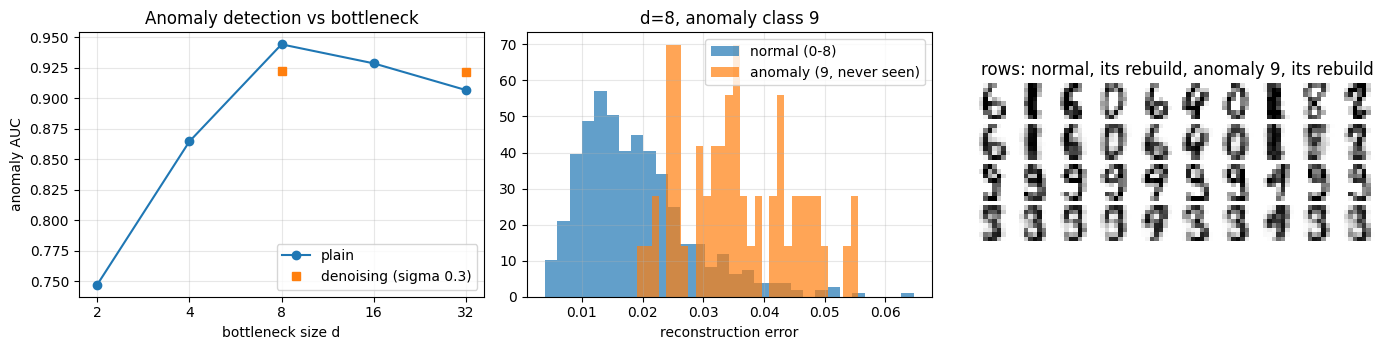

In [2]:
def train_ae(Xnp, dim, noise=0.0, epochs=40, seed=0, bs=128):
    # encoder 64-64-d, decoder d-64-64 with a sigmoid output; mean squared error to the CLEAN input
    torch.manual_seed(seed)
    enc = make_mlp([64, 64, dim]); dec = make_mlp([dim, 64, 64], nn.Sigmoid())
    opt = torch.optim.Adam(list(enc.parameters()) + list(dec.parameters()), 3e-3)
    Xt = torch.tensor(Xnp)
    for ep in range(epochs):
        perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), bs):
            xb = Xt[perm[i:i + bs]]
            xin = (xb + noise * torch.randn_like(xb)).clamp(0, 1) if noise > 0 else xb
            loss = F.mse_loss(dec(enc(xin)), xb)
            opt.zero_grad(); loss.backward(); opt.step()
    return enc, dec

def recon_err(model, Xnp, noise=0.0):
    enc, dec = model
    with torch.no_grad():
        xt = torch.tensor(Xnp)
        xin = (xt + noise * torch.randn_like(xt)).clamp(0, 1) if noise > 0 else xt
        return ((dec(enc(xin)) - xt) ** 2).mean(1).numpy()

HOLD = [5, 9]
DIMS = [2, 4, 8, 16, 32]
results = {}                # (hold, dim, noise) -> AUC
models = {}
for hold in HOLD:
    normal = itr[ytr != hold]
    for dim, noise in [(d, 0.0) for d in DIMS] + [(8, 0.3), (32, 0.3)]:
        m = train_ae(X[normal], dim, noise)
        err = recon_err(m, Xte)
        results[(hold, dim, noise)] = roc_auc_score(yte == hold, err)
        models[(hold, dim, noise)] = m

print("AUC of the reconstruction error as anomaly score (mean over held-out classes 5 and 9)")
print("bottleneck d | plain AE | denoising AE (sigma 0.3)")
for dim in DIMS:
    plain = np.mean([results[(h, dim, 0.0)] for h in HOLD])
    den = np.mean([results[(h, dim, 0.3)] for h in HOLD]) if dim in (8, 32) else float("nan")
    print(f"{dim:>12} | {plain:8.3f} | {den:8.3f}")
print("per class, d=8 plain:", {h: round(results[(h, 8, 0.0)], 3) for h in HOLD}, "| elapsed", round(time.time() - T0), "s")

# denoising itself: error against the clean image when the input is noisy (sigma 0.3), models trained without class 9
torch.manual_seed(1)
for noise in (0.0, 0.3):
    e = recon_err(models[(9, 32, noise)], Xte, noise=0.3)[yte != 9].mean()
    print(f"d=32 AE trained with noise {noise}: error vs clean image when the input has noise 0.3 = {e:.4f}")

fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
for noise, lab, st in [(0.0, "plain", "o-"), (0.3, "denoising (sigma 0.3)", "s")]:
    ds = DIMS if noise == 0 else [8, 32]
    axs[0].plot(ds, [np.mean([results[(h, d, noise)] for h in HOLD]) for d in ds], st, label=lab)
axs[0].set_xscale("log", base=2); axs[0].set_xticks(DIMS); axs[0].set_xticklabels(DIMS)
axs[0].set_xlabel("bottleneck size d"); axs[0].set_ylabel("anomaly AUC"); axs[0].set_title("Anomaly detection vs bottleneck"); axs[0].legend()
err = recon_err(models[(9, 8, 0.0)], Xte)
axs[1].hist(err[yte != 9], bins=30, alpha=0.7, label="normal (0-8)", density=True)
axs[1].hist(err[yte == 9], bins=30, alpha=0.7, label="anomaly (9, never seen)", density=True)
axs[1].set_xlabel("reconstruction error"); axs[1].set_title("d=8, anomaly class 9"); axs[1].legend()
enc, dec = models[(9, 8, 0.0)]
nrm = Xte[yte != 9][:10]; ano = Xte[yte == 9][:10]
with torch.no_grad():
    rows = [nrm, dec(enc(torch.tensor(nrm))).numpy(), ano, dec(enc(torch.tensor(ano))).numpy()]
axs[2].imshow(montage(np.concatenate(rows), 10), cmap="gray", vmin=0, vmax=1); axs[2].axis("off"); axs[2].grid(False)
axs[2].set_title("rows: normal, its rebuild, anomaly 9, its rebuild")
plt.tight_layout(); plt.show()

**Reading.** Look at the table first. A very small bottleneck ($d = 2$) cannot even rebuild the normal digits, so its error is high for everything and the anomalies are not singled out. The AUC rises as the bottleneck grows, peaks at $d = 8$ (0.94) and then falls (0.93 at 16, 0.91 at 32): with a wide bottleneck the network starts to copy, and it rebuilds the unseen class too, which is the failure that the bottleneck was meant to prevent. The best $d$ is a compromise and it depends on the data, which is why it is tuned on validation data that contains some anomalies, when such data exist. The denoising autoencoder is the useful variant when the bottleneck is wide: because it cannot copy its input, it keeps a high AUC at $d = 32$ where the plain one tends to lose it (0.922 against 0.907 in our run, while at $d = 8$ the plain one is better, 0.944 against 0.922; and on inputs with noise the denoising model rebuilds the clean image with about 20 % lower error, 0.027 against 0.033). Honest caveats: two held-out classes and one seed per setting is a small experiment, so differences of a few hundredths of AUC are within noise; the rebuilds in the picture show the mechanism (the rebuilt 9 is pulled towards a normal-looking digit), not a precise ranking. A 9 is also genuinely close to a 4 or a 7, so the AUC cannot be expected to reach 1.0 on these 8x8 pixels.

## 3. Variational autoencoders: ELBO, reparameterisation, blurriness

A plain autoencoder places each training image at some point of the code space, but nothing says what lies **between** the points. Decode a random code and you often get garbage. A **variational autoencoder** (Kingma and Welling, 2014) fixes this by making the code a **distribution**.

The encoder no longer outputs one code but the parameters of a Gaussian: a mean $\boldsymbol{\mu}(\mathbf{x})$ and a log-variance $\log\boldsymbol{\sigma}^2(\mathbf{x})$ (both vectors with one entry per latent dimension; $\boldsymbol{\sigma}$ is the vector of standard deviations). A code is **sampled**, $\mathbf{z} \sim \mathcal{N}(\boldsymbol{\mu}, \boldsymbol{\sigma}^2)$, and the decoder must rebuild $\mathbf{x}$ from it. Training maximises the **ELBO** (evidence lower bound), a lower bound on the log-probability $\log p(\mathbf{x})$ that the model gives to the data:

$$\text{ELBO}(\mathbf{x}) = \underbrace{\mathbb{E}_{q(\mathbf{z}\mid\mathbf{x})}\big[\log p(\mathbf{x}\mid\mathbf{z})\big]}_{\text{reconstruction}} \;-\; \underbrace{D_{\mathrm{KL}}\big(q(\mathbf{z}\mid\mathbf{x}) \,\Vert\, p(\mathbf{z})\big)}_{\text{KL term}}$$

Here $q(\mathbf{z}\mid\mathbf{x})$ is the encoder's Gaussian, $p(\mathbf{x}\mid\mathbf{z})$ is the decoder, and $p(\mathbf{z}) = \mathcal{N}(\mathbf{0}, \mathbf{I})$ is the **prior** that we want codes to follow. $D_{\mathrm{KL}}$ is the **Kullback-Leibler divergence**, a measure of how far one distribution is from another (zero only when they are equal). For two Gaussians it has a closed form, which is what the code uses:

$$D_{\mathrm{KL}} = -\tfrac{1}{2}\sum_{j}\big(1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2\big)$$

where $j$ runs over the latent dimensions. The two terms pull in opposite directions. The reconstruction term wants precise codes (small $\sigma$, distinct $\mu$ for every image). The KL term wants every code distribution to look like the prior, which squeezes all images into overlapping blobs around the origin. The overlap is exactly what makes the space between the codes meaningful: a point between two images lands in a region the decoder has seen.

**The reparameterisation trick.** Sampling $\mathbf{z}$ is a random operation, and gradients cannot flow through a random draw. The trick is to draw the randomness separately, $\boldsymbol{\epsilon} \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$, and compute $\mathbf{z} = \boldsymbol{\mu} + \boldsymbol{\sigma}\odot\boldsymbol{\epsilon}$ ($\odot$ is element-wise multiplication). Now $\mathbf{z}$ is a differentiable function of $\boldsymbol{\mu}$ and $\boldsymbol{\sigma}$ and ordinary backpropagation works.

**The blurriness trade-off.** We treat each pixel as a Bernoulli probability, so the reconstruction term is the binary cross-entropy summed over the 64 pixels. We add a weight $\beta$ in front of the KL term (the "$\beta$-VAE" of Higgins et al., 2017; $\beta = 1$ is the true ELBO). A small $\beta$ gives sharp reconstructions but a patchy latent space; a large $\beta$ gives a tidy latent space but reconstructions that average over everything the code cannot distinguish, which looks **blurry**. We measure four things for $\beta \in \{0.1, 1, 4\}$ with a 2D latent space (so that we can draw it) and for $\beta = 1$ with 8 latent dimensions: the test reconstruction error, the KL cost per image in nats, the sharpness (total variation, as a fraction of that of real digits), and how digit-like the judge finds samples drawn from the prior. We also decode straight lines between pairs of images of different digits, for the VAE and for a plain 2D autoencoder, and measure how often the judge is confident about the images in the middle of the line.

config (latent dim, beta) | test MSE | KL nats | sharpness vs real | judge conf. on prior samples | conf. mid-interpolation
                 (2, 0.1) | 0.0397   |    5.8  |  0.80             | 0.661                        | 0.611


                 (2, 1.0) | 0.0399   |    2.4  |  0.76             | 0.629                        | 0.570
                 (2, 4.0) | 0.0744   |    0.0  |  0.53             | 0.301                        | 0.297


                 (8, 1.0) | 0.0259   |    3.3  |  0.80             | 0.674                        | 0.638
            plain AE, d=2 | 0.0426   |    n/a  |  0.78             | (no prior)                   | 0.531
elapsed 69 s


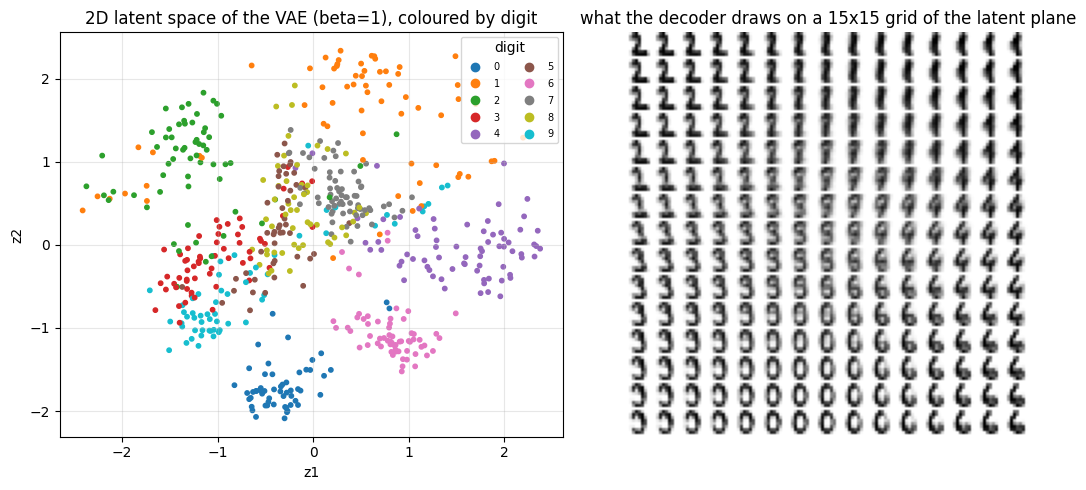

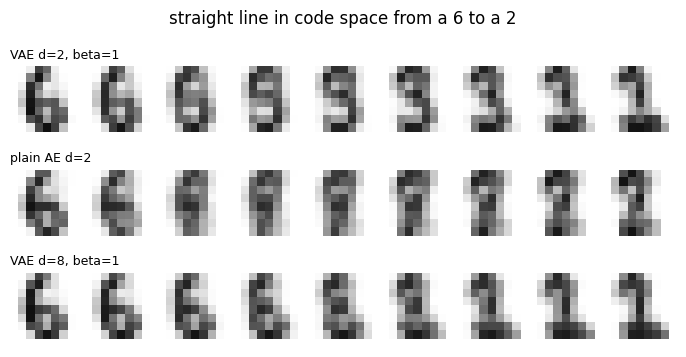

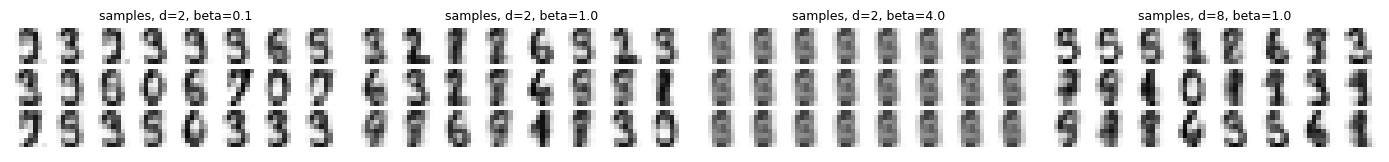

In [3]:
class VAE(nn.Module):
    def __init__(self, zdim, h=128):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(64, h), nn.ReLU())
        self.mu = nn.Linear(h, zdim); self.logvar = nn.Linear(h, zdim)
        self.dec = make_mlp([zdim, h, 64])               # outputs logits, the sigmoid is inside the loss
    def encode(self, x):
        h = self.body(x); return self.mu(h), self.logvar(h)
    def forward(self, x):
        mu, logvar = self.encode(x)
        eps = torch.randn_like(mu)
        z = mu + torch.exp(0.5 * logvar) * eps           # reparameterisation trick
        return self.dec(z), mu, logvar

def vae_loss(logits, x, mu, logvar, beta):
    rec = F.binary_cross_entropy_with_logits(logits, x, reduction="none").sum(1)   # -log p(x|z), summed over pixels
    kl = -0.5 * (1 + logvar - mu ** 2 - logvar.exp()).sum(1)                       # closed-form Gaussian KL
    return (rec + beta * kl).mean(), rec.mean(), kl.mean()

def train_vae(zdim, beta, epochs=80, seed=0, bs=128):
    torch.manual_seed(seed)
    m = VAE(zdim); opt = torch.optim.Adam(m.parameters(), 3e-3)
    Xt = torch.tensor(Xtr)
    for ep in range(epochs):
        perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), bs):
            xb = Xt[perm[i:i + bs]]
            logits, mu, lv = m(xb)
            loss, _, _ = vae_loss(logits, xb, mu, lv, beta)
            opt.zero_grad(); loss.backward(); opt.step()
    return m

CONFIGS = [(2, 0.1), (2, 1.0), (2, 4.0), (8, 1.0)]
vaes = {c: train_vae(*c) for c in CONFIGS}
ae2 = train_ae(Xtr, 2, epochs=40)                        # plain 2D autoencoder for the interpolation comparison

def mid_confidence(decode_path, pairs):
    # judge's mean max-probability on the middle of the straight line between two images of different classes
    confs = []
    for a, b in pairs:
        imgs = decode_path(a, b)
        confs.append(judge.predict_proba(imgs[2:-2]).max(1).mean())
    return float(np.mean(confs))

rs = np.random.RandomState(1)
pairs = []
while len(pairs) < 60:
    a, b = rs.choice(len(Xte), 2, replace=False)
    if yte[a] != yte[b]:
        pairs.append((a, b))
ts = np.linspace(0, 1, 9)

def vae_path(m):
    def f(a, b):
        with torch.no_grad():
            za = m.encode(torch.tensor(Xte[[a]]))[0]; zb = m.encode(torch.tensor(Xte[[b]]))[0]
            return torch.sigmoid(m.dec(torch.stack([(1 - t) * za[0] + t * zb[0] for t in ts]))).numpy()
    return f
def ae_path(m):
    def f(a, b):
        enc, dec = m
        with torch.no_grad():
            za = enc(torch.tensor(Xte[[a]])); zb = enc(torch.tensor(Xte[[b]]))
            return dec(torch.stack([(1 - t) * za[0] + t * zb[0] for t in ts])).numpy()
    return f

print("config (latent dim, beta) | test MSE | KL nats | sharpness vs real | judge conf. on prior samples | conf. mid-interpolation")
torch.manual_seed(5)
for c, m in vaes.items():
    with torch.no_grad():
        xt = torch.tensor(Xte)
        mu, lv = m.encode(xt)
        rec = torch.sigmoid(m.dec(mu)).numpy()
        kl = (-0.5 * (1 + lv - mu ** 2 - lv.exp()).sum(1)).mean().item()
        samp = torch.sigmoid(m.dec(torch.randn(500, c[0]))).numpy()
    print(f"{str(c):>25} | {((rec - Xte) ** 2).mean():.4f}   | {kl:6.1f}  | {tv(rec) / TV_REAL:5.2f}             | {judge.predict_proba(samp).max(1).mean():.3f}                        | {mid_confidence(vae_path(m), pairs):.3f}")
with torch.no_grad():
    rec = ae2[1](ae2[0](torch.tensor(Xte))).numpy()
print(f"{'plain AE, d=2':>25} | {((rec - Xte) ** 2).mean():.4f}   |    n/a  | {tv(rec) / TV_REAL:5.2f}             | (no prior)                   | {mid_confidence(ae_path(ae2), pairs):.3f}")
print("elapsed", round(time.time() - T0), "s")

# figures: latent map of the beta=1 2D VAE, decoded grid over the plane, interpolation strips, prior samples
m = vaes[(2, 1.0)]
with torch.no_grad():
    mu_all = m.encode(torch.tensor(Xte))[0].numpy()
    lim = 2.6; g = np.linspace(-lim, lim, 15)
    grid_imgs = torch.sigmoid(m.dec(torch.tensor([[a, b] for b in g[::-1] for a in g], dtype=torch.float32))).numpy()
fig, axs = plt.subplots(1, 2, figsize=(11, 5))
sc = axs[0].scatter(mu_all[:, 0], mu_all[:, 1], c=yte, cmap="tab10", s=10)
axs[0].set_title("2D latent space of the VAE (beta=1), coloured by digit"); axs[0].set_xlabel("z1"); axs[0].set_ylabel("z2")
axs[0].legend(*sc.legend_elements(), ncol=2, fontsize=7, title="digit", loc="upper right")
axs[1].imshow(montage(grid_imgs, 15), cmap="gray", vmin=0, vmax=1); axs[1].axis("off"); axs[1].grid(False)
axs[1].set_title("what the decoder draws on a 15x15 grid of the latent plane")
plt.tight_layout(); plt.show()

a, b = pairs[3]
strips = [vae_path(vaes[(2, 1.0)])(a, b), ae_path(ae2)(a, b), vae_path(vaes[(8, 1.0)])(a, b)]
fig, axs = plt.subplots(3, 1, figsize=(9, 3.6))
for ax, s, t in zip(axs, strips, ["VAE d=2, beta=1", "plain AE d=2", "VAE d=8, beta=1"]):
    ax.imshow(montage(s, 9), cmap="gray", vmin=0, vmax=1); ax.axis("off"); ax.grid(False); ax.set_title(t, fontsize=9, loc="left")
fig.suptitle(f"straight line in code space from a {yte[a]} to a {yte[b]}"); plt.tight_layout(); plt.show()

torch.manual_seed(2)
fig, axs = plt.subplots(1, 4, figsize=(14, 2.6))
for ax, c in zip(axs, CONFIGS):
    with torch.no_grad():
        s = torch.sigmoid(vaes[c].dec(torch.randn(24, c[0]))).numpy()
    ax.imshow(montage(s, 8), cmap="gray", vmin=0, vmax=1); ax.axis("off"); ax.grid(False); ax.set_title(f"samples, d={c[0]}, beta={c[1]}", fontsize=9)
plt.tight_layout(); plt.show()

**Reading.** The table tells the trade-off, and one row is a surprise. Going from $\beta = 0.1$ to $\beta = 1$ costs little (test error 0.0397 to 0.0399, sharpness 0.80 to 0.76 of the real digits) and the KL cost per image falls from 5.8 to 2.4 nats. At $\beta = 4$ the model suffers **posterior collapse**: the KL term is 0.0, every code equals the prior, the decoder ignores the code and outputs the same blurry average digit (error 0.074, sharpness 0.53, the judge is unsure of everything). That is the blurriness trade-off at its extreme: when the code is made too cheap to be informative, the best pixel-wise answer is the mean. The 2D map shows why a VAE is a generator: neighbouring codes decode to similar digits and the grid drawn by the decoder moves smoothly from one digit to another. In the straight-line test the judge is more confident in the middle of the VAE paths (0.57 to 0.64) than of the plain 2D autoencoder (0.53), a modest gap on one seed and 60 pairs. The VAE with 8 latent dimensions rebuilds best (error 0.026) and its prior samples are the most recognisable (judge confidence 0.67, against 0.90 for real digits), but the differences between $\beta = 0.1$ and $\beta = 1$ in sample quality are within what we would expect from seed noise. The blur is not a bug: with a pixel-wise likelihood, the best answer to "what is the pixel here" under uncertainty is the average, and an average of two strokes is a smear. GANs, next, replace the pixel-wise likelihood and pay for it elsewhere.

## 4. Generative adversarial networks: a two-player game

A VAE judges its output with a fixed formula (pixel error). A **GAN** (Goodfellow et al., 2014) lets a second network learn how to judge. Two players:

* the **generator** $G$ turns random noise $\mathbf{z}$ into a fake sample $G(\mathbf{z})$;
* the **discriminator** $D$ looks at a sample and outputs the probability that it is real.

The original objective is a **minimax game** over a value function $V$:

$$\min_G \max_D \; V(D, G) = \mathbb{E}_{\mathbf{x} \sim p_{\text{data}}}\big[\log D(\mathbf{x})\big] + \mathbb{E}_{\mathbf{z} \sim p_{\mathbf{z}}}\big[\log\big(1 - D(G(\mathbf{z}))\big)\big]$$

where $p_{\text{data}}$ is the data distribution and $p_{\mathbf{z}}$ the noise distribution. $D$ is trained to tell real from fake; $G$ is trained to fool $D$. At the ideal equilibrium $G$ reproduces the data distribution exactly and $D$ outputs $\tfrac12$ everywhere. In practice $G$ is trained with the **non-saturating** loss $-\log D(G(\mathbf{z}))$, which gives useful gradients when $D$ is winning, and the two networks take alternating Adam steps.

There is no loss to minimise, only a game, and that is where the trouble comes from:

* **Instability.** Each player's best move depends on the other. Updating both with gradient descent can cycle forever instead of converging, the loss curves are not a measure of quality, and a discriminator that becomes too good leaves the generator with no useful gradient.
* **Mode collapse.** The generator is rewarded for fooling $D$ *right now*. If one output that fools $D$ is found, producing only that is a fine local strategy. The generator then covers a few **modes** (clusters) of the data and ignores the rest; the discriminator learns to reject that output, the generator jumps to another one, and so on.

**Toy 1: eight Gaussians on a ring.** The target is eight small clusters ($\sigma = 0.1$) on a circle of radius 2. We can see everything and measure exactly. For 2,000 generated points we compute **modes covered** (clusters that receive at least 1 % of the points, out of 8) and the **hit rate** (fraction of points within three $\sigma$ of some cluster centre, a measure of quality). We compare three settings: a **balanced** GAN (both networks with learning rate $10^{-3}$); the same GAN with an **unbalanced** learning-rate pair (generator $5\times10^{-3}$, discriminator $5\times10^{-4}$); and the same unbalanced pair with the **hinge loss** variant: $D$ minimises $\max(0, 1 - D(\mathbf{x})) + \max(0, 1 + D(G(\mathbf{z})))$ and $G$ minimises $-D(G(\mathbf{z}))$ (Lim and Ye, 2017), a margin loss on raw scores that has no saturating sigmoid.

setting                  | modes covered per seed (of 8) | hit rate per seed | mean modes


balanced GAN             | [8, 8, 8] | [0.8, 0.78, 0.81] | 8.0


unbalanced GAN           | [1, 1, 1] | [0.7, 0.15, 0.1] | 1.0


unbalanced, hinge loss   | [1, 2, 1] | [0.83, 0.12, 0.12] | 1.3
elapsed 196 s


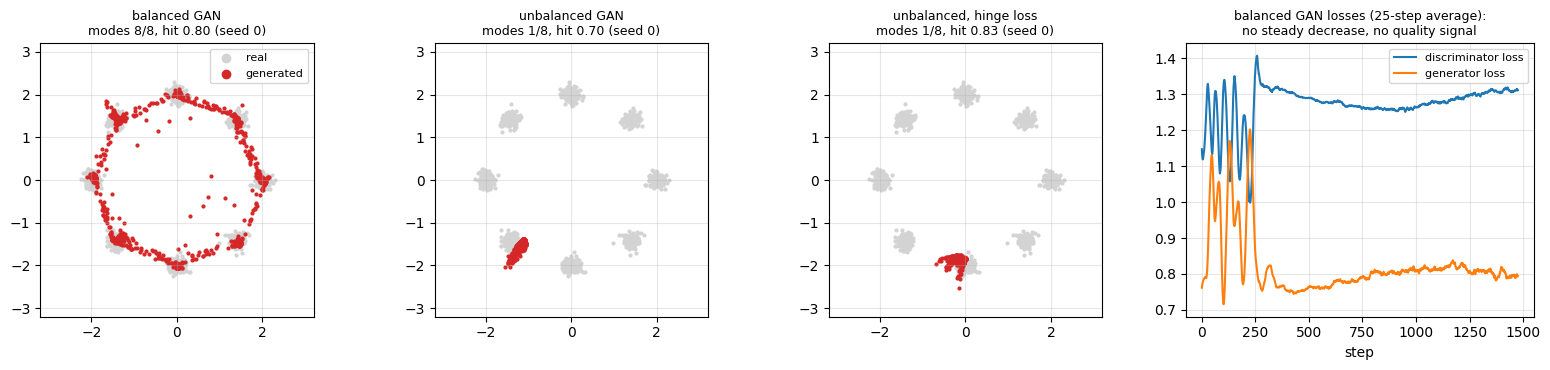

In [4]:
ANG = np.arange(8) * 2 * np.pi / 8
MODES = np.stack([2 * np.cos(ANG), 2 * np.sin(ANG)], 1).astype(np.float32)
SIG = 0.1

def real_toy(n, g):
    k = torch.randint(0, 8, (n,), generator=g)
    return torch.tensor(MODES)[k] + SIG * torch.randn(n, 2, generator=g)

def coverage(x):
    d = torch.cdist(x, torch.tensor(MODES)); near = d.min(1)
    hit = near.values < 3 * SIG
    cnt = torch.bincount(near.indices[hit], minlength=8)
    return int((cnt >= 0.01 * len(x)).sum()), float(hit.float().mean())

def train_toy(kind, seed, steps, lrg=1e-3, lrd=1e-3, ncritic=1, track=False):
    torch.manual_seed(seed); g = torch.Generator().manual_seed(seed)
    G = make_mlp([2, 64, 64, 2]); D = make_mlp([2, 64, 64, 1])
    betas = (0.5, 0.999) if kind in ("gan", "hinge") else (0.0, 0.9)
    oG = torch.optim.Adam(G.parameters(), lrg, betas=betas); oD = torch.optim.Adam(D.parameters(), lrd, betas=betas)
    bce = nn.BCEWithLogitsLoss(); B = 128
    hist = []
    for s in range(steps):
        for _ in range(ncritic):
            xr = real_toy(B, g); xf = G(torch.randn(B, 2)).detach()
            if kind == "gan":
                ld = bce(D(xr), torch.ones(B, 1)) + bce(D(xf), torch.zeros(B, 1))
            elif kind == "hinge":
                ld = F.relu(1 - D(xr)).mean() + F.relu(1 + D(xf)).mean()
            else:       # Wasserstein critic with gradient penalty (Gulrajani et al., 2017)
                a = torch.rand(B, 1); xi = (a * xr + (1 - a) * xf).requires_grad_(True)
                grad = torch.autograd.grad(D(xi).sum(), xi, create_graph=True)[0]
                ld = D(xf).mean() - D(xr).mean() + 10 * ((grad.norm(dim=1) - 1) ** 2).mean()
            oD.zero_grad(); ld.backward(); oD.step()
        out = D(G(torch.randn(B, 2)))
        lg = bce(out, torch.ones(B, 1)) if kind == "gan" else -out.mean()
        oG.zero_grad(); lg.backward(); oG.step()
        if track:
            hist.append((ld.item(), lg.item()))
    with torch.no_grad():
        return G, coverage(G(torch.randn(2000, 2))), np.array(hist)

SETTINGS = [("balanced GAN", "gan", dict(steps=1500)),
            ("unbalanced GAN", "gan", dict(steps=1000, lrg=5e-3, lrd=5e-4)),
            ("unbalanced, hinge loss", "hinge", dict(steps=1000, lrg=5e-3, lrd=5e-4))]
toy = {}
print("setting                  | modes covered per seed (of 8) | hit rate per seed | mean modes")
for name, kind, kw in SETTINGS:
    outs = [train_toy(kind, s, track=(s == 0), **kw) for s in range(3)]
    toy[name] = outs
    print(f"{name:24} | {[o[1][0] for o in outs]} | {[round(o[1][1], 2) for o in outs]} | {np.mean([o[1][0] for o in outs]):.1f}")
print("elapsed", round(time.time() - T0), "s")

fig, axs = plt.subplots(1, 4, figsize=(16, 3.8))
rt = real_toy(1000, torch.Generator().manual_seed(9)).numpy()
for ax, (name, _, _) in zip(axs[:3], SETTINGS):
    G = toy[name][0][0]
    with torch.no_grad():
        p = G(torch.randn(1000, 2)).numpy()
    ax.scatter(rt[:, 0], rt[:, 1], s=4, c="lightgray", label="real"); ax.scatter(p[:, 0], p[:, 1], s=4, c="C3", label="generated")
    ax.set_title(f"{name}\nmodes {toy[name][0][1][0]}/8, hit {toy[name][0][1][1]:.2f} (seed 0)", fontsize=9); ax.set_xlim(-3.2, 3.2); ax.set_ylim(-3.2, 3.2); ax.set_aspect("equal")
axs[0].legend(markerscale=3, fontsize=8)
h = toy["balanced GAN"][0][2]
k = 25; sm = lambda v: np.convolve(v, np.ones(k) / k, mode="valid")
axs[3].plot(sm(h[:, 0]), label="discriminator loss"); axs[3].plot(sm(h[:, 1]), label="generator loss")
axs[3].set_xlabel("step"); axs[3].set_title("balanced GAN losses (25-step average):\nno steady decrease, no quality signal", fontsize=9); axs[3].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading.** In the balanced setting the vanilla GAN found all eight clusters in all three seeds (hit rate about 0.8), which is worth saying plainly: mode collapse is not guaranteed, it appears when the balance between the players is off or the target is harder. With the unbalanced learning rates the generator ran ahead of the discriminator and all three seeds collapsed to a single mode (and in two of them the hit rate is only 0.1 to 0.15: the collapsed point sits between clusters). The hinge loss under the same unbalanced setting did not rescue it (1, 2 and 1 modes): a different loss does not replace a sensible balance. Three seeds is a rough indication, not a proof. The last panel is the practical lesson about instability: the losses wobble and do not fall steadily, and a low generator loss can mean either "good" or "the discriminator is lost", so unlike supervised training you cannot judge a GAN by its loss. You judge by looking at samples and by task measures such as the coverage and hit rate used here, the judge confidence on digits below, or published scores such as FID (Fréchet inception distance) on large image sets.

**The Wasserstein variant.** Arjovsky et al. (2017) argued that the original loss is a poor guide because, when real and fake distributions barely overlap, the divergence it implies is flat and the generator gets no gradient. They replace the discriminator by a **critic** that outputs an unbounded score and approximates the **Wasserstein distance** (the cost of moving the generated distribution onto the real one, "earth mover's distance"); the critic must be **1-Lipschitz** (its output may not change faster than its input), enforced originally by clipping the weights and later, much better, by a **gradient penalty** that pushes the critic's gradient norm to 1 (Gulrajani et al., 2017). The critic loss is $\mathbb{E}[D(G(\mathbf{z}))] - \mathbb{E}[D(\mathbf{x})] + \lambda\,\mathbb{E}[(\lVert\nabla D(\hat{\mathbf{x}})\rVert - 1)^2]$ with $\lambda = 10$ and $\hat{\mathbf{x}}$ a random point on the line between a real and a fake sample. The critic loss then correlates with sample quality, which makes it a usable training curve. The price is a double backward pass and several critic steps per generator step. The `train_toy` function above already contains it (`kind="wgan"`); the next cell runs it once with a short budget.

In [5]:
t = time.time()
Gw, (modes_w, hit_w), _ = train_toy("wgan", 0, 1200, ncritic=2)
print(f"Wasserstein critic with gradient penalty, 1200 generator steps, 2 critic steps each, seed 0: modes {modes_w}/8, hit rate {hit_w:.2f}  ({time.time() - t:.0f} s)")

Wasserstein critic with gradient penalty, 1200 generator steps, 2 critic steps each, seed 0: modes 1/8, hit rate 0.04  (33 s)


**Reading.** This run failed: 1 mode of 8 and a hit rate near zero after 1,200 generator steps. We report it because it is the honest result of a short budget, one seed and untuned settings, not because the Wasserstein loss is worse: the original papers train for tens of thousands of steps with carefully chosen critic steps and learning rates, and the gradient-penalty critic is slower to sharpen the generator than the vanilla loss. Exercise 6 asks you to give it a longer run. What the cell does show is the cost: a double backward pass and several critic steps per generator step.

**Toy 2: digits.** The same game on the 64-pixel digits: a generator with a 16-number noise input and a discriminator, both small fully connected networks. We cannot count modes by eye, so we use the judge: the **class coverage** is the number of digit classes (of 10) that receive at least 2 % of the samples by the judge's prediction, the **class entropy** (as a fraction of the maximum, $\ln 10$) says how evenly the classes are produced, the **judge confidence** says how digit-like the samples are, and the **diversity** is the mean distance between random pairs of generated images divided by the same for real images (a collapsed generator has diversity far below 1). We train the balanced setting and a generator-heavy one (the same unbalanced learning rates as above).

setting                          | classes of 10 | class entropy | judge conf. | diversity
real test digits                 |            10 |         1.00 | 0.903       | 1.00
balanced (2e-3 / 2e-3)           |            10 |         0.98 | 0.720       | 0.97
generator-heavy (1e-2 / 5e-4)    |             9 |         0.83 | 0.592       | 1.03
elapsed 268 s


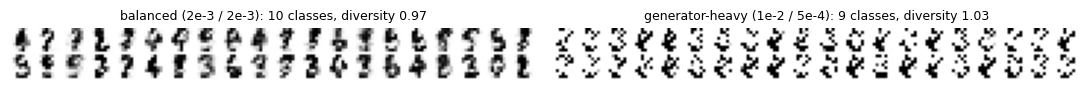

In [6]:
def train_digit_gan(seed, steps, lrg, lrd, B=64):
    torch.manual_seed(seed)
    G = make_mlp([16, 128, 64], nn.Sigmoid()); D = make_mlp([64, 128, 1])
    oG = torch.optim.Adam(G.parameters(), lrg, betas=(0.5, 0.999)); oD = torch.optim.Adam(D.parameters(), lrd, betas=(0.5, 0.999))
    bce = nn.BCEWithLogitsLoss(); Xt = torch.tensor(Xtr)
    for s in range(steps):
        xr = Xt[torch.randint(0, len(Xt), (B,))]; xf = G(torch.randn(B, 16)).detach()
        ld = bce(D(xr), torch.ones(B, 1)) + bce(D(xf), torch.zeros(B, 1))
        oD.zero_grad(); ld.backward(); oD.step()
        lg = bce(D(G(torch.randn(B, 16))), torch.ones(B, 1))
        oG.zero_grad(); lg.backward(); oG.step()
    return G

def pair_dist(a):
    i = np.random.RandomState(0).permutation(len(a)); return float(np.linalg.norm(a[i[:250]] - a[i[250:500]], axis=1).mean())

def gan_report(G):
    with torch.no_grad():
        s = G(torch.randn(1000, 16)).numpy()
    pr = judge.predict_proba(s); share = np.bincount(pr.argmax(1), minlength=10) / len(s)
    ent = -(share[share > 0] * np.log(share[share > 0])).sum() / np.log(10)
    return s, dict(classes=int((share >= 0.02).sum()), entropy=ent, conf=pr.max(1).mean(), diversity=pair_dist(s) / pair_dist(Xte), share=share)

dg = {}
for name, lrg, lrd in [("balanced (2e-3 / 2e-3)", 2e-3, 2e-3), ("generator-heavy (1e-2 / 5e-4)", 1e-2, 5e-4)]:
    dg[name] = gan_report(train_digit_gan(0, 1500, lrg, lrd))
real_share = np.bincount(yte, minlength=10) / len(yte)
print(f"{'setting':32} | classes of 10 | class entropy | judge conf. | diversity")
print(f"{'real test digits':32} | {int((real_share >= 0.02).sum()):13d} | {-(real_share * np.log(real_share)).sum() / np.log(10):12.2f} | {judge.predict_proba(Xte).max(1).mean():.3f}       | 1.00")
for name, (s, r) in dg.items():
    print(f"{name:32} | {r['classes']:13d} | {r['entropy']:12.2f} | {r['conf']:.3f}       | {r['diversity']:.2f}")
print("elapsed", round(time.time() - T0), "s")

fig, axs = plt.subplots(1, 2, figsize=(11, 3))
for ax, (name, (s, r)) in zip(axs, dg.items()):
    ax.imshow(montage(s[:40], 20), cmap="gray", vmin=0, vmax=1); ax.axis("off"); ax.grid(False)
    ax.set_title(f"{name}: {r['classes']} classes, diversity {r['diversity']:.2f}", fontsize=9)
plt.tight_layout(); plt.show()

**Reading.** The balanced GAN produces digits of all ten classes in nearly even shares (class entropy 0.98) with a judge confidence of 0.72, higher than for the VAE samples (0.63 to 0.67) but well below real digits (0.90): the generated digits are recognisable but often ambiguous. The generator-heavy run is **not** a collapse on digits: it still produces nine classes, the diversity is 1.03, but the shares are uneven (entropy 0.83) and the judge confidence drops to 0.59, so the samples are less digit-like. We did not obtain a clean mode collapse on digits in this run, and the 2D ring above is where the failure is measured. A diversity near 1 is also reached by noisy images, which is why it is read together with the judge confidence. One seed and 1,500 steps: read these as an illustration of the measurements. Real GANs (DCGAN, StyleGAN and others) solve these problems with convolutional architectures, normalisation, careful balancing and many tricks; since 2021 diffusion models (module 05 of Neural Networks 1002) have replaced them for most image generation precisely because their training is a plain regression with none of this fragility.

## 5. Self-supervised learning: contrastive learning with SimCLR

Labels are expensive: a radiologist, a chemist or a lawyer has to produce each one. Unlabelled data are almost free. **Self-supervised learning** invents a **pretext task** whose answer comes from the data itself, trains a network on it, and then reuses the network as a **feature extractor** for the real task, for which only a few labels are needed. Autoencoders were an early pretext task (rebuild the input). Others: predict a masked word (BERT), predict the next word (module 10 of Neural Networks 1001), predict the rotation of an image, fill in a masked patch. The most influential family for images until recently is **contrastive learning**.

**The idea.** Take an image and make two random **augmented views** of it (shifted, rotated, rescaled, dimmed, noisy). Two views of the same image form a **positive pair**; views of different images in the batch are **negatives**. Train an encoder so that the two views of one image get nearby representations and views of different images get distant ones. To succeed, the encoder must ignore everything the augmentations change (position, brightness) and keep what stays (the identity of the digit). **The augmentations are the supervision**: they say what should not matter.

**SimCLR** (Chen et al., 2020) is the simplest recipe. Encode both views with an encoder $f$ (whose output is the **representation** we will keep), pass it through a small **projection head** $h$ (thrown away after training), and L2-normalise the result into vectors $\mathbf{z}_i$. For a batch of $N$ images there are $2N$ views. The loss for a view $i$ whose positive partner is $j(i)$ is the **InfoNCE** loss (van den Oord et al., 2018), also called NT-Xent (normalised temperature-scaled cross-entropy):

$$\ell_i = -\log \frac{\exp\big(\mathbf{z}_i\cdot\mathbf{z}_{j(i)} / \tau\big)}{\sum_{k \neq i} \exp\big(\mathbf{z}_i\cdot\mathbf{z}_k / \tau\big)}$$

The sum in the denominator runs over all $2N - 1$ other views, and $\tau$ is the **temperature** (a small positive number, here 0.2) that sharpens the softmax. This is a classification problem: out of $2N - 1$ candidates, pick the true partner. It is a lower bound on the mutual information between the two views, which is where the name comes from.

**Making the task need invariance.** On the plain 8x8 digits, a linear classifier on raw pixels is already excellent (97 %), so there is little for a representation to add, and an honest experiment would show a tie. Real images are not like that: the object is anywhere in the frame, at any scale. We mimic it by pasting every digit at a **random position inside a 12x12 canvas**, so that the same digit appears at 25 different places and raw pixels are no longer linearly separable. The SimCLR augmentations (random rotation of up to 12 degrees, scale 0.85 to 1.15, translation of up to about 2 pixels, brightness 0.6 to 1.4, Gaussian noise) are written below in a few lines with `affine_grid` and `grid_sample`, which apply a different random affine transformation to every image of the batch at once.

**The measurement: a linear-probe curve.** To compare representations fairly we freeze them and train only a **linear classifier** (a logistic regression) on top, with $n$ labelled examples, for $n$ from 10 to the full 1,200. This **linear probe** tests how much of the class structure is already linearly readable. We compare, at each $n$:

* **raw pixels** (no representation learning, the baseline);
* **supervised from scratch**: the same encoder architecture followed by a linear layer, trained end to end with only the $n$ labels (no unlabelled data used);
* **untrained encoder**: the same architecture with random weights (a control: how much does the architecture alone give?);
* **autoencoder features**: the encoder of an autoencoder (32-number bottleneck) trained on the 1,200 images without labels;
* **SimCLR with weak augmentation**: noise only, no geometry (a control: without the right augmentations contrastive learning learns little);
* **SimCLR with the full augmentations**.

For each $n$ we average over 3 random draws of the labelled subset.

SimCLR trained twice in 28 s; elapsed 297 s
cosine similarity of the 64-d representations of two geometric views: same image 0.76 vs different images 0.56  (strong-augmentation encoder)
                                                                       same image 0.55 vs different images 0.45  (weak-augmentation encoder)


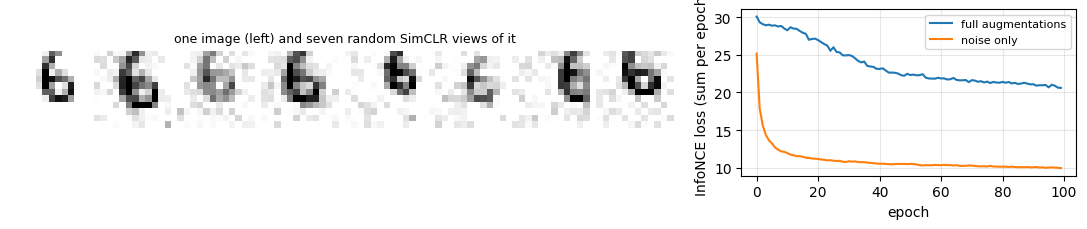

In [7]:
# the same digits pasted at a random position inside a 12x12 canvas
crng = np.random.RandomState(3)
XS = np.zeros((len(X), 12, 12), np.float32)
for i in range(len(X)):
    a, b = crng.randint(0, 5, 2)
    XS[i, a:a + 8, b:b + 8] = X[i].reshape(8, 8)
XS = XS.reshape(len(X), 144)
XStr, XSte = XS[itr], XS[ite]

def augment(x, geometric=True):
    # a different random view of every image in the batch
    n = len(x); im = x.view(n, 1, 12, 12)
    if geometric:
        ang = (torch.rand(n) * 2 - 1) * math.radians(12)
        sc = torch.empty(n).uniform_(0.85, 1.15)
        tx = (torch.rand(n) * 2 - 1) * 0.35; ty = (torch.rand(n) * 2 - 1) * 0.35     # in units of half the canvas (0.35 = about 2 pixels)
        th = torch.zeros(n, 2, 3)
        th[:, 0, 0] = torch.cos(ang) / sc; th[:, 0, 1] = -torch.sin(ang) / sc
        th[:, 1, 0] = torch.sin(ang) / sc; th[:, 1, 1] = torch.cos(ang) / sc
        th[:, 0, 2] = tx; th[:, 1, 2] = ty
        im = F.grid_sample(im, F.affine_grid(th, im.shape, align_corners=False), align_corners=False)
        im = im * torch.empty(n, 1, 1, 1).uniform_(0.6, 1.4)
    im = im + 0.1 * torch.randn_like(im)
    return im.clamp(0, 1).view(n, 144)

def info_nce(z1, z2, tau=0.2):
    # NT-Xent: each of the 2N views must pick out its partner among the other 2N-1 views
    z = F.normalize(torch.cat([z1, z2]), dim=1); n = len(z1)
    s = z @ z.T / tau
    s.fill_diagonal_(-1e9)                                           # a view is not its own candidate
    target = torch.cat([torch.arange(n, 2 * n), torch.arange(0, n)])
    return F.cross_entropy(s, target)

def make_encoder():
    return nn.Sequential(nn.Linear(144, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU())

def train_simclr(geometric, epochs=100, seed=0, bs=256):
    torch.manual_seed(seed)
    enc = make_encoder(); head = nn.Linear(64, 32)
    opt = torch.optim.Adam(list(enc.parameters()) + list(head.parameters()), 2e-3)
    Xt = torch.tensor(XStr); losses = []
    for ep in range(epochs):
        perm = torch.randperm(len(Xt)); tot = 0
        for i in range(0, len(Xt), bs):
            xb = Xt[perm[i:i + bs]]
            loss = info_nce(head(enc(augment(xb, geometric))), head(enc(augment(xb, geometric))))
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item()
        losses.append(tot)
    return enc, losses

t = time.time()
enc_strong, loss_strong = train_simclr(True)
enc_weak, loss_weak = train_simclr(False)
print(f"SimCLR trained twice in {time.time() - t:.0f} s; elapsed {time.time() - T0:.0f} s")

# what the augmentations do, and what the contrastive encoder learned about them
torch.manual_seed(4)
one = torch.tensor(XSte[:1]).repeat(7, 1)
views = torch.cat([torch.tensor(XSte[:1]), augment(one)]).numpy()
with torch.no_grad():
    za = F.normalize(enc_strong(augment(torch.tensor(XSte))), dim=1); zb = F.normalize(enc_strong(augment(torch.tensor(XSte))), dim=1)
    wa = F.normalize(enc_weak(augment(torch.tensor(XSte))), dim=1); wb = F.normalize(enc_weak(augment(torch.tensor(XSte))), dim=1)
    perm = torch.randperm(len(za))
    pos_s, neg_s = (za * zb).sum(1).mean().item(), (za * zb[perm]).sum(1).mean().item()
    pos_w, neg_w = (wa * wb).sum(1).mean().item(), (wa * wb[perm]).sum(1).mean().item()
print(f"cosine similarity of the 64-d representations of two geometric views: same image {pos_s:.2f} vs different images {neg_s:.2f}  (strong-augmentation encoder)")
print(f"                                                                       same image {pos_w:.2f} vs different images {neg_w:.2f}  (weak-augmentation encoder)")
fig, axs = plt.subplots(1, 2, figsize=(11, 2.4), gridspec_kw={"width_ratios": [2, 1]})
axs[0].imshow(montage(views, 8, side=12), cmap="gray", vmin=0, vmax=1); axs[0].axis("off"); axs[0].grid(False)
axs[0].set_title("one image (left) and seven random SimCLR views of it", fontsize=9)
axs[1].plot(loss_strong, label="full augmentations"); axs[1].plot(loss_weak, label="noise only"); axs[1].set_xlabel("epoch"); axs[1].set_ylabel("InfoNCE loss (sum per epoch)"); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

test accuracy (mean over 3 random draws of the labelled set); columns: number of labels
method                             10     20     50    100    200    400   1200
raw pixels                      0.131  0.156  0.192  0.235  0.251  0.269  0.323
untrained encoder               0.126  0.139  0.183  0.217  0.246  0.286  0.357
autoencoder features            0.137  0.159  0.194  0.194  0.216  0.255  0.307
SimCLR, noise only              0.146  0.175  0.227  0.271  0.342  0.396  0.451
SimCLR, full augmentations      0.276  0.360  0.546  0.652  0.769  0.806  0.851
supervised from scratch         0.135  0.168  0.227  0.296  0.405  0.583  0.833
largest std over draws, any cell: 0.062 | elapsed 352 s


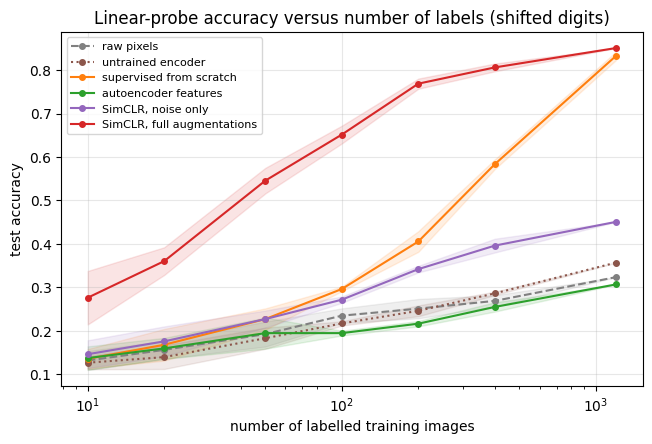

In [8]:
# the comparison methods
def sup_features_free(Xs_, ys_, seed):
    # supervised from scratch: same architecture + linear layer, trained end to end on n labelled images only
    torch.manual_seed(seed)
    net = nn.Sequential(make_encoder(), nn.Linear(64, 10))
    opt = torch.optim.Adam(net.parameters(), 3e-3, weight_decay=1e-3)
    xt, yt = torch.tensor(Xs_), torch.tensor(ys_)
    for _ in range(200):
        loss = F.cross_entropy(net(xt), yt); opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        return (net(torch.tensor(XSte)).argmax(1).numpy() == yte).mean()

# autoencoder on the 12x12 canvas (144 inputs), 32-number bottleneck, no labels
torch.manual_seed(0)
ae_enc = make_mlp([144, 128, 32]); ae_dec = make_mlp([32, 128, 144], nn.Sigmoid())
opt = torch.optim.Adam(list(ae_enc.parameters()) + list(ae_dec.parameters()), 3e-3)
Xt = torch.tensor(XStr)
for ep in range(40):
    perm = torch.randperm(len(Xt))
    for i in range(0, len(Xt), 128):
        xb = Xt[perm[i:i + 128]]
        loss = F.mse_loss(ae_dec(ae_enc(xb)), xb); opt.zero_grad(); loss.backward(); opt.step()

torch.manual_seed(0)
enc_random = make_encoder()
with torch.no_grad():
    feats = {"raw pixels": XS,
             "untrained encoder": enc_random(torch.tensor(XS)).numpy(),
             "autoencoder features": ae_enc(torch.tensor(XS)).numpy(),
             "SimCLR, noise only": enc_weak(torch.tensor(XS)).numpy(),
             "SimCLR, full augmentations": enc_strong(torch.tensor(XS)).numpy()}

def probe(Fm, sub):
    sc = StandardScaler().fit(Fm[itr][sub])
    clf = LogisticRegression(max_iter=500).fit(sc.transform(Fm[itr][sub]), ytr[sub])
    return clf.score(sc.transform(Fm[ite]), yte)

NS = [10, 20, 50, 100, 200, 400, 1200]
DRAWS = 3
acc = {k: np.zeros((len(NS), DRAWS)) for k in list(feats) + ["supervised from scratch"]}
for a, n in enumerate(NS):
    for d in range(DRAWS):
        sub = np.random.RandomState(100 * d + n).choice(1200, n, replace=False)
        for k, Fm in feats.items():
            acc[k][a, d] = probe(Fm, sub)
        acc["supervised from scratch"][a, d] = sup_features_free(XStr[sub], ytr[sub], d)

print("test accuracy (mean over 3 random draws of the labelled set); columns: number of labels")
print(f"{'method':30}" + "".join(f"{n:>7}" for n in NS))
for k, v in acc.items():
    print(f"{k:30}" + "".join(f"{m:7.3f}" for m in v.mean(1)))
print("largest std over draws, any cell:", round(max(v.std(1).max() for v in acc.values()), 3), "| elapsed", round(time.time() - T0), "s")

fig, ax = plt.subplots(figsize=(7.5, 4.6))
styles = {"raw pixels": ("gray", "--"), "untrained encoder": ("C5", ":"), "supervised from scratch": ("C1", "-"), "autoencoder features": ("C2", "-"),
          "SimCLR, noise only": ("C4", "-"), "SimCLR, full augmentations": ("C3", "-")}
for k, (c, ls) in styles.items():
    m, s = acc[k].mean(1), acc[k].std(1)
    ax.plot(NS, m, ls, color=c, marker="o", ms=4, label=k); ax.fill_between(NS, m - s, m + s, color=c, alpha=0.12)
ax.set_xscale("log"); ax.set_xlabel("number of labelled training images"); ax.set_ylabel("test accuracy"); ax.set_title("Linear-probe accuracy versus number of labels (shifted digits)")
ax.legend(fontsize=8); plt.show()

**Reading.** On shifted digits, raw pixels are a poor starting point (32 % with all 1,200 labels, the same digit lights up different pixels at different positions) and the contrastive representation with the full augmentations is far ahead at small label counts: 28 % with 10 labels against 13 % for every other method, 55 % with 50 labels against 19 to 23 %, and 85 % with all labels. This is the label-efficiency argument for self-supervised learning in one picture: the 1,200 unlabelled images were worth hundreds of labels. The controls keep us honest. The untrained encoder and the autoencoder features add nothing over raw pixels: an autoencoder is rewarded for rebuilding **every** pixel, including where the digit is, so its code keeps the nuisance (position) that the classifier needs to ignore. SimCLR with noise-only augmentation learns a little (45 % against 32 % at the end) but nowhere near the full version, which confirms that the gain comes from the augmentations, that is from what we told the network not to care about; the positive-pair cosine similarity (0.76 against 0.56 for different images, against 0.55 and 0.45 for the noise-only encoder) says the same. Supervised training from scratch is no better than raw pixels with few labels and catches up with the contrastive curve only with all labels (83 % against 85 %, within the draw-to-draw spread). Two caveats: first, the size of the gap is a property of this data and this choice of nuisance (position); on the centred 8x8 digits a raw-pixel probe is hard to beat (in a preliminary run the three were within a few points of each other, 96 to 97 % with all labels). Second, 3 draws and one training seed per method means that small differences between the lower curves are noise (the largest standard deviation over draws is 0.06); the gap to the top curve at small $n$ is far larger. The real SimCLR paper reports the same effect on ImageNet at a very different scale (a ResNet-50 network, 1.28 million images, batches of thousands of images, hundreds of epochs on many accelerators).

## 6. CLIP: aligning images and text

Contrastive learning does not need the two views to be two pictures. **CLIP** (Radford et al., 2021) uses an **image** and its **caption** as the two views of the same "thing". It has two encoders, an image encoder $f_{\text{img}}$ and a text encoder $f_{\text{txt}}$, each followed by a projection to a shared space. For a batch of $N$ pairs it forms the $N \times N$ matrix of cosine similarities between every image and every caption, multiplies it by a learned scale $1/\tau$, and applies the InfoNCE loss twice: each image must pick its caption among the $N$ captions, and each caption must pick its image among the $N$ images (the average of the two cross-entropies). The only difference to SimCLR is that the two views come from different modalities. The original model was trained on 400 million image-text pairs collected from the web.

What you gain is a model that can be **told in words what to look for**. To classify an image into $K$ classes with no training for that task (**zero-shot classification**), write one sentence per class ("a photo of a dog", "a photo of a cat"), encode them with the text encoder, and pick the class whose sentence is most similar to the image in the shared space. The class list is just text, so it can be changed at will.

**Part 1: a CLIP in miniature, from scratch.** We pair each digit image with a random caption generated from templates, for example "a handwritten seven", "the digit seven", "an odd digit", "a small digit" (0 to 4) or "this is an even and large number". The image encoder is a small fully connected network. The text encoder is the simplest thing that works: a learned embedding for each word, **averaged** over the words of the caption (it ignores word order, which real CLIP does not; it uses a Transformer), followed by a small network. After training we test on unseen images and on **prompts that were never used in training**: the template "this is the number seven" (all of its words occur in training, but never in this combination) and prompts that name only a **property** ("an even digit") instead of the digit itself. That is the zero-shot idea in miniature. One technical detail: a batch may contain two images of the same digit with the same caption, which the loss treats as a false negative; at batch size 128 with ten classes this happens often, and it limits the final accuracy (real CLIP has the same issue with duplicates, at a much lower rate thanks to its huge, diverse batches).

tiny CLIP trained in 700 steps (375 s elapsed). Zero-shot accuracy on the 597 test digits:
  10 classes, prompt 'a handwritten <digit>' (seen in training)        : 0.985
  10 classes, prompt 'this is the number <digit>' (never seen as such): 0.980
  even versus odd, prompts 'an even digit' / 'an odd digit'           : 0.990  (chance 0.5)
  small versus large, prompts 'a small digit' / 'a large digit'       : 0.985  (chance 0.5)
  supervised judge with labels, for reference                         : 0.975  (chance 0.1)


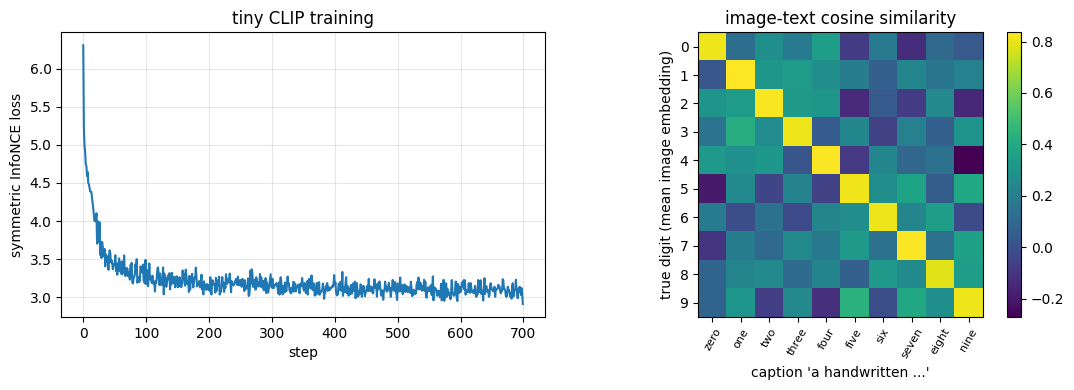

In [9]:
WORDS = ["zero", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine"]
TEMPLATES = ["a handwritten {w}", "the digit {w}", "a picture of the number {w}", "{w}", "{w} is {p}", "an {p} digit",
             "a {s} digit", "this is an {p} and {s} number", "{w} is {s}"]
def parity(k): return "even" if k % 2 == 0 else "odd"
def size(k): return "small" if k < 5 else "large"

def caption(k, r):
    t = TEMPLATES[r.randint(len(TEMPLATES))]
    p = parity(k); s = size(k)
    t = t.replace("an {p}", "an " + p).replace("a {s}", "a " + s)           # keep the article simple: "an even", "an odd"
    return t.format(w=WORDS[k], p=p, s=s)

vocab = sorted({w for k in range(10) for t in TEMPLATES for w in t.format(w=WORDS[k], p=parity(k), s=size(k)).split()}
               | {"this", "is", "the", "number", "an", "a", "even", "odd", "small", "large"})
w2i = {w: i for i, w in enumerate(vocab)}
MAXLEN = 8
def tokenize(caps):
    ids = torch.zeros(len(caps), MAXLEN, dtype=torch.long); mask = torch.zeros(len(caps), MAXLEN)
    for r, c in enumerate(caps):
        for j, w in enumerate(c.split()[:MAXLEN]):
            ids[r, j] = w2i[w]; mask[r, j] = 1
    return ids, mask

class TinyCLIP(nn.Module):
    def __init__(self, dim=32):
        super().__init__()
        self.img = make_mlp([64, 128, dim])
        self.emb = nn.Embedding(len(vocab), 32); self.txt = make_mlp([32, 64, dim])
        self.logit_scale = nn.Parameter(torch.tensor(math.log(1 / 0.07)))      # the learned temperature
    def encode_image(self, x): return F.normalize(self.img(x), dim=1)
    def encode_text(self, caps):
        ids, mask = tokenize(caps)
        e = (self.emb(ids) * mask[..., None]).sum(1) / mask.sum(1, keepdim=True)   # mean of the word embeddings
        return F.normalize(self.txt(e), dim=1)

torch.manual_seed(0); r = np.random.RandomState(0)
clip = TinyCLIP(); opt = torch.optim.Adam(clip.parameters(), 3e-3)
Xt = torch.tensor(Xtr); B = 128; hist = []
for step in range(700):
    idx = torch.randint(0, len(Xt), (B,))
    caps = [caption(int(ytr[i]), r) for i in idx]
    zi = clip.encode_image(Xt[idx]); zt = clip.encode_text(caps)
    logits = clip.logit_scale.exp().clamp(max=100) * zi @ zt.T
    tgt = torch.arange(B)
    loss = (F.cross_entropy(logits, tgt) + F.cross_entropy(logits.T, tgt)) / 2          # image->text and text->image
    opt.zero_grad(); loss.backward(); opt.step(); hist.append(loss.item())

with torch.no_grad():
    zi = clip.encode_image(torch.tensor(Xte))
    def zs(prompts): return (zi @ clip.encode_text(prompts).T)
    a_seen = (zs([f"a handwritten {w}" for w in WORDS]).argmax(1).numpy() == yte).mean()
    a_new = (zs([f"this is the number {w}" for w in WORDS]).argmax(1).numpy() == yte).mean()
    a_par = (zs(["an even digit", "an odd digit"]).argmax(1).numpy() == (yte % 2)).mean()
    a_siz = (zs(["a small digit", "a large digit"]).argmax(1).numpy() == (yte >= 5)).mean()
    sims = zs([f"a handwritten {w}" for w in WORDS]).numpy()
    mean_img = np.stack([zi[yte == k].mean(0).numpy() for k in range(10)])
    zt_all = clip.encode_text([f"a handwritten {w}" for w in WORDS]).numpy()
print(f"tiny CLIP trained in 700 steps ({time.time() - T0:.0f} s elapsed). Zero-shot accuracy on the 597 test digits:")
print(f"  10 classes, prompt 'a handwritten <digit>' (seen in training)        : {a_seen:.3f}")
print(f"  10 classes, prompt 'this is the number <digit>' (never seen as such): {a_new:.3f}")
print(f"  even versus odd, prompts 'an even digit' / 'an odd digit'           : {a_par:.3f}  (chance 0.5)")
print(f"  small versus large, prompts 'a small digit' / 'a large digit'       : {a_siz:.3f}  (chance 0.5)")
print(f"  supervised judge with labels, for reference                         : {judge.score(Xte, yte):.3f}  (chance 0.1)")

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(hist); axs[0].set_xlabel("step"); axs[0].set_ylabel("symmetric InfoNCE loss"); axs[0].set_title("tiny CLIP training")
im = axs[1].imshow(mean_img @ zt_all.T, cmap="viridis"); axs[1].set_xticks(range(10)); axs[1].set_xticklabels(WORDS, rotation=60, fontsize=8)
axs[1].set_yticks(range(10)); axs[1].set_ylabel("true digit (mean image embedding)"); axs[1].set_xlabel("caption 'a handwritten ...'"); axs[1].grid(False)
axs[1].set_title("image-text cosine similarity"); plt.colorbar(im, ax=axs[1]); plt.tight_layout(); plt.show()

**Reading.** The diagonal of the similarity matrix is the whole idea: an image of a 3 is most similar to the caption "three", having learned this only from pairs. The zero-shot rows show that the shared space is more than a lookup table. A prompt template that never occurred in this combination still classifies at 98 %, and a prompt that names only a property ("an even digit") separates even from odd digits at 99 %, because the words "even" and "odd" were aligned with the images of those digits through the captions that mention them, in the same space as the digit names. Be careful about the comparison with the supervised judge (97.5 %): our captions contain the label word, so the caption is as informative as a label; the difference is that the supervision arrives as text and can be queried with new sentences. The in-batch duplicates (same digit, same caption) act as false negatives but did not stop training. This is a toy: the captions come from nine templates and a 30-word vocabulary. The point of the real model is that the same machinery, trained on 400 million web captions, handles open-ended text.

**Part 2: a real pre-trained CLIP, on the CPU.** Training a useful CLIP takes hundreds of accelerator-days, so we use the released checkpoint **openai/clip-vit-base-patch32** ([model card](https://huggingface.co/openai/clip-vit-base-patch32), [paper](https://arxiv.org/abs/2103.00020)): a Vision Transformer with 32-pixel patches as image encoder and a Transformer text encoder, about 150 million parameters in total. The model card declares no licence of its own; OpenAI's code repository [github.com/openai/CLIP](https://github.com/openai/CLIP) is under the **MIT licence** (check the terms yourself before any commercial use of the weights). The card says the model is intended for research, that its performance varies by class and task, and that it carries documented biases, so it should not be deployed without studying the task. The first call downloads about 600 MB once into the Hugging Face cache (`~/.cache/huggingface`) and needs the `transformers` package; if the network or the package is missing, the cell prints why and does nothing.

We classify a few photographs bundled with the libraries scikit-image (the astronaut Eileen Collins, public domain NASA photograph; a coffee cup; a cat, "chelsea", CC0; a rocket launch, SpaceX Falcon 9, CC0; all from [scikit-image data](https://scikit-image.org/docs/stable/api/skimage.data.html), see the licence notes there) and scikit-learn (a Chinese temple and a flower, Creative Commons images, see [the scikit-learn datasets page](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_sample_images.html)) against a list of candidate sentences that **we write on the spot and the model never trained on**: the zero-shot classifier. Then we run it on the 8x8 digits (upscaled to 224 pixels) with the prompts "a photo of the number N", and compare with our tiny CLIP, which saw the digits in training.

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 6782.13it/s]

loaded openai/clip-vit-base-patch32 (151 M parameters) in 6 s


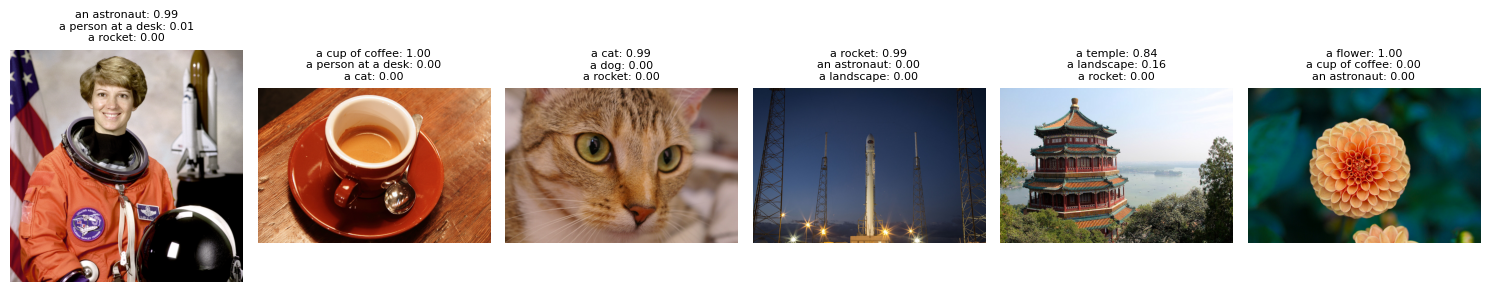

zero-shot top-1 per image: {'astronaut': 'an astronaut', 'coffee': 'a cup of coffee', 'cat': 'a cat', 'rocket': 'a rocket', 'temple': 'a temple', 'flower': 'a flower'}


real CLIP, zero-shot on 150 test digits (never trained on this task): accuracy 0.133   | tiny CLIP (saw these digits): 0.985   | logistic regression with 1,200 labels: 0.975
elapsed for this cell 107 s; total 507 s


In [10]:
import os
try:
    from transformers import CLIPModel, CLIPProcessor
    from PIL import Image
    from skimage import data as skdata
    from sklearn.datasets import load_sample_images
    torch.set_num_threads(2)
    t = time.time()
    NAME = "openai/clip-vit-base-patch32"
    model = CLIPModel.from_pretrained(NAME).eval(); proc = CLIPProcessor.from_pretrained(NAME)
    print(f"loaded {NAME} ({sum(p.numel() for p in model.parameters()) / 1e6:.0f} M parameters) in {time.time() - t:.0f} s")

    sk = load_sample_images()
    photos = {"astronaut": skdata.astronaut(), "coffee": skdata.coffee(), "cat": skdata.chelsea(), "rocket": skdata.rocket(),
              "temple": sk.images[0], "flower": sk.images[1]}
    labels = ["a cat", "a dog", "an astronaut", "a cup of coffee", "a rocket", "a temple", "a flower", "a car", "a landscape", "a person at a desk"]
    prompts = [f"a photo of {l}" for l in labels]
    with torch.no_grad():
        inp = proc(text=prompts, images=[Image.fromarray(p) for p in photos.values()], return_tensors="pt", padding=True)
        out = model(**inp)
        probs = out.logits_per_image.softmax(1).numpy()
    fig, axs = plt.subplots(1, len(photos), figsize=(15, 3.3))
    for ax, (name, im), p in zip(axs, photos.items(), probs):
        top = p.argsort()[::-1][:3]
        ax.imshow(im); ax.axis("off"); ax.grid(False)
        ax.set_title("\n".join(f"{labels[j]}: {p[j]:.2f}" for j in top), fontsize=8)
    plt.tight_layout(); plt.show()
    print("zero-shot top-1 per image:", {n: labels[p.argmax()] for n, p in zip(photos, probs)})

    # the same model on the digits, upscaled from 8x8 to 224x224, dark ink on white
    sel = np.random.RandomState(0).choice(len(Xte), 150, replace=False)
    imgs = [Image.fromarray((255 * (1 - Xte[i].reshape(8, 8))).astype(np.uint8)).resize((224, 224), Image.NEAREST).convert("RGB") for i in sel]
    dprompts = [f"a photo of the number {k}" for k in range(10)]
    pred = []
    with torch.no_grad():
        for i in range(0, len(imgs), 25):
            o = model(**proc(text=dprompts, images=imgs[i:i + 25], return_tensors="pt", padding=True))
            pred.append(o.logits_per_image.argmax(1).numpy())
    pred = np.concatenate(pred)
    print(f"real CLIP, zero-shot on {len(sel)} test digits (never trained on this task): accuracy {(pred == yte[sel]).mean():.3f}   | tiny CLIP (saw these digits): {a_seen:.3f}   | logistic regression with 1,200 labels: {judge.score(Xte, yte):.3f}")
    print(f"elapsed for this cell {time.time() - t:.0f} s; total {time.time() - T0:.0f} s")
except Exception as e:
    print("Real CLIP part skipped:", type(e).__name__, str(e)[:200])
    print("It needs `pip install transformers pillow` and network access once to download the checkpoint (about 600 MB).")

**Reading.** In our run all six photographs are classified correctly from sentences we invented a minute ago, with no training for this task: that is the practical meaning of zero-shot. The probabilities depend on the candidate list (it is a softmax over our ten sentences, so a photo whose true description is not among the options is forced onto the nearest wrong one) and on the wording of the prompt, which is why the real CLIP paper spends a section on prompt engineering. On the digits, an 8x8 image blown up to 224 pixels is far from the web photographs the model was trained on, the zero-shot accuracy is close to chance (13 % in our run, chance is 10 %), far below our tiny CLIP that was trained on exactly this data (98 %) and a supervised classifier. A sample of 150 digits gives a standard error of about 3 points, so the real model is at best slightly above chance here. This is a negative result worth keeping: zero-shot works for what looks like the training distribution, and a blocky 8x8 digit does not. Zero-shot trades the last points of accuracy on a narrow, well-defined task for flexibility, and it fails on specialised or synthetic images such as these, where fine-tuning or a probe on its features would be the next step. Always check the model card before using such a model on people or in a product: the CLIP card lists the known limitations and biases.

## 7. Where this leads: diffusion and generalist models

Each idea of this notebook is a building block of the models you will meet next.

* **From autoencoders and VAEs to latent diffusion.** Modern image generators do not work on pixels. A (variational, and in practice adversarially trained) autoencoder compresses every image to a small latent grid, and the generative model works inside that latent space, which is far cheaper. The VAE decoder of this notebook is the part that turns the final latent back into a picture. The same models also borrow the denoising idea of section 2: a **diffusion model** is a denoising autoencoder trained on many noise levels, applied repeatedly. Module 05 of Neural Networks 1002 builds one.
* **From GANs to diffusion.** The adversarial game gave sharp images and unstable training; diffusion replaced the game by a regression that is stable and covers all the modes, at the cost of many sampling steps. GAN discriminators survive as perceptual losses and in the decoders of the autoencoders above.
* **From contrastive pre-training to text-conditioned generation.** The text encoder of a CLIP-style model is the standard way to tell a generator what to draw: the prompt is encoded into the shared space (or its sequence of token vectors) and the diffusion network is conditioned on it with cross-attention, which module 05 of Neural Networks 1002 studies with a real checkpoint. Contrastive text-image alignment is also how images enter large language models.
* **From self-supervised learning to generalist models.** The recipe "predict part of the data from the rest, at scale, with no labels" is the common root of language models, vision-language models and the generalist models of module 15 of Neural Networks 1002: the pretext task changes (next word, masked patch, matching caption) but the economics stay the same, unlabelled data pay for the representation and a few labels or a prompt specialise it.

## 8. Key takeaways, exercises, references

**Key takeaways**

* A bottleneck forces an autoencoder to learn structure instead of copying, and the **reconstruction error** of a model trained on normal data is a ready-made **anomaly score**; too wide a bottleneck lets the model rebuild anomalies too, and denoising is the way to keep a wide one honest.
* A **VAE** adds a KL term to the reconstruction loss (the ELBO) and uses the **reparameterisation trick** to backpropagate through sampling. The KL term makes the latent space smooth and sample-able, and it is exactly what makes samples **blurrier**: the weight $\beta$ trades sharpness against a well-organised latent space.
* A **GAN** replaces a fixed loss by a learned critic. Its images are sharper, but training is a game, not an optimisation: the loss curves say little, balance matters, and **mode collapse** (few clusters covered) is measured by coverage, hit rate and diversity, not by the loss. The hinge loss did not rescue an unbalanced game in our run, and our short Wasserstein run failed; both need care and a longer budget.
* **Contrastive learning** with an **InfoNCE** loss learns representations from unlabelled data; **the augmentations define what the representation ignores**. In our linear-probe curve, features from the right augmentations were worth hundreds of labels, and the same architecture trained only on the labels was the worst at small $n$; the control with noise-only augmentation showed no such benefit.
* **CLIP** applies the same loss to image-caption pairs, and a shared space of images and text gives **zero-shot** classification with prompts written at will. The real checkpoint works on photographs and is much weaker on tiny synthetic digits.
* All numbers here come from tiny data, single or few seeds and short training: they show mechanisms and the direction of effects, not production-level performance.

**Exercises**

1. In section 2, hold out the class 1 (a simple digit) instead of 5 and 9. Is the anomaly AUC higher or lower, and why does the reconstruction error of a thin stroke behave differently? Add $d = 64$ and $d = 128$ and see where the plain autoencoder breaks down.
2. Replace the noise in the denoising autoencoder by **masking** (set a random quarter of the pixels to zero) and compare the AUC at $d = 32$. Which corruption is better for anomaly detection?
3. In section 3, train the VAE with $\beta = 0$ (a plain autoencoder with a random code). What happens to the KL term and to the prior samples? Then try **KL annealing**: increase $\beta$ linearly from 0 to 1 during the first 30 epochs.
4. Compute for each VAE the **active dimensions** of the 8-d code (those whose posterior mean varies more than 0.1 across the test set). How many are used? This is "posterior collapse" in a mild form.
5. In section 4, run the balanced GAN on the ring with 8 seeds instead of 3 and report the distribution of modes covered. Then change the number of discriminator steps per generator step to 5. When does the game stabilise, and when does it stall?
6. Run the Wasserstein critic of `train_toy` for 4,000 generator steps. Does its hit rate catch up with the vanilla GAN? Plot the critic loss: does it track the quality of the samples, as claimed?
7. In section 5, change the temperature $\tau$ to 0.05 and to 1.0, and the batch size to 64 and 1,200. Which setting hurts most at 20 labels? Why do contrastive methods like large batches (more negatives)?
8. Add a new augmentation to SimCLR (for example random erasing of a 3x3 patch) and one that **contradicts** the task (for example rotating by up to 180 degrees: a 6 and a 9 now look alike). Measure the linear probe at 50 labels. Does a wrong augmentation hurt?
9. In section 6, give the tiny CLIP a caption template that is wrong for 10 % of the images (a random digit name). How robust is the zero-shot accuracy to noisy captions? (Real web captions are noisy too.)
10. Use the real CLIP with your own photographs and a candidate list in which the correct description is absent. What does the model answer, and why is the probability still high?

**References**

* Hinton, G. E. and Salakhutdinov, R. R. (2006). Reducing the dimensionality of data with neural networks. *Science* 313(5786), 504-507: https://doi.org/10.1126/science.1127647
* Vincent, P., Larochelle, H., Bengio, Y. and Manzagol, P.-A. (2008). Extracting and composing robust features with denoising autoencoders. *ICML*, 1096-1103: https://doi.org/10.1145/1390156.1390294
* Kingma, D. P. and Welling, M. (2014). Auto-encoding variational Bayes. *ICLR*. arXiv:1312.6114: https://arxiv.org/abs/1312.6114
* Higgins, I. et al. (2017). beta-VAE: learning basic visual concepts with a constrained variational framework. *ICLR*: https://openreview.net/forum?id=Sy2fzU9gl
* Goodfellow, I. et al. (2014). Generative adversarial nets. *NeurIPS*. arXiv:1406.2661: https://arxiv.org/abs/1406.2661
* Arjovsky, M., Chintala, S. and Bottou, L. (2017). Wasserstein GAN. arXiv:1701.07875: https://arxiv.org/abs/1701.07875
* Gulrajani, I., Ahmed, F., Arjovsky, M., Dumoulin, V. and Courville, A. (2017). Improved training of Wasserstein GANs. *NeurIPS*. arXiv:1704.00028: https://arxiv.org/abs/1704.00028
* Lim, J. H. and Ye, J. C. (2017). Geometric GAN (the hinge loss for GANs). arXiv:1705.02894: https://arxiv.org/abs/1705.02894
* van den Oord, A., Li, Y. and Vinyals, O. (2018). Representation learning with contrastive predictive coding (InfoNCE). arXiv:1807.03748: https://arxiv.org/abs/1807.03748
* Chen, T., Kornblith, S., Norouzi, M. and Hinton, G. (2020). A simple framework for contrastive learning of visual representations (SimCLR). *ICML*. arXiv:2002.05709: https://arxiv.org/abs/2002.05709
* Radford, A. et al. (2021). Learning transferable visual models from natural language supervision (CLIP). *ICML*. arXiv:2103.00020: https://arxiv.org/abs/2103.00020
* OpenAI (2021). CLIP ViT-B/32 model card: https://huggingface.co/openai/clip-vit-base-patch32 ; code and licence (MIT): https://github.com/openai/CLIP
* Alpaydin, E. and Kaynak, C. (1998). Optical recognition of handwritten digits. UCI Machine Learning Repository (CC BY 4.0): https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits
* Pedregosa, F. et al. (2011). Scikit-learn: machine learning in Python. *JMLR* 12, 2825-2830: https://jmlr.org/papers/v12/pedregosa11a.html
* van der Walt, S. et al. (2014). scikit-image: image processing in Python. *PeerJ* 2:e453: https://doi.org/10.7717/peerj.453